# **BikeWale Web Scraping Project**

In [1]:
import requests
from bs4 import BeautifulSoup
import re
import json as jsonlib
import time
import random
import os
import pandas as pd

In [2]:
BASE_URL = "https://www.bikewale.com"

headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/137.0.0.0 Safari/537.36",
    "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,*/*;q=0.8",
    "Accept-Language": "en-US,en;q=0.9",
    "Accept-Encoding": "gzip, deflate",
}

REQUEST_DELAY = (2, 4)  # random delay range in seconds between requests
RAW_CSV_PATH = "bikewale_all_brands.csv"
FAILED_URLS_PATH = "failed_urls.txt"

def polite_sleep():
    time.sleep(random.uniform(*REQUEST_DELAY))

# Known multi-word / special-casing brands. Extend as needed.
BRAND_DISPLAY_NAMES = {
    "royalenfield": "Royal Enfield",
    "tvs": "TVS",
    "honda": "Honda",
    "yamaha": "Yamaha",
    "bajaj": "Bajaj",
    "hero": "Hero",
    "ather": "Ather",
    "ktm": "KTM",
    "triumph": "Triumph",
    "suzuki": "Suzuki",
    "ampere": "Ampere",
    "aprilia": "Aprilia",
    "benelli": "Benelli",
    "bgauss": "BGauss",
    "bmw": "BMW",
    "bounce": "Bounce",
    "brixtonmotorcycles": "Brixton Motorcycles",
    "bsa": "BSA",
    "cfmoto": "CFMoto",
    "ducati": "Ducati",
    "evolet": "Evolet",
    "gemopai": "Gemopai",
    "harleydavidson": "Harley-Davidson",
    "hopelectric": "Hop Electric",
    "husqvarna": "Husqvarna",
    "indian": "Indian",
    "ivoomi": "iVOOMi",
    "jawa": "Jawa",
    "joyebike": "Joy e-bike",
    "kawasaki": "Kawasaki",
    "keeway": "Keeway",
    "kinetic": "Kinetic",
    "kineticgreen": "Kinetic Green",
    "lambretta": "Lambretta",
    "lectrix": "Lectrix",
    "matter": "Matter",
    "motoguzzi": "Moto Guzzi",
    "motomorini": "Moto Morini",
    "norton": "Norton",
    "numeros": "Numeros",
    "oben": "Oben",
    "odysse": "Odysse",
    "okinawa": "Okinawa",
    "ola": "OLA",
    "opgmobility": "OPG Mobility",
    "pureev": "PURE EV",
    "qjmotor": "QJ Motor",
    "quantumenergy": "Quantum Energy",
    "revolt": "Revolt",
    "river": "River",
    "simpleenergy": "Simple Energy",
    "ultraviolette": "Ultraviolette",
    "vespa": "Vespa",
    "vida": "VIDA",
    "vinfast": "Vinfast",
    "yezdi": "Yezdi",
    "zontes": "Zontes",
}

def get_brand_display(brand_slug):
    """brand_slug example: 'royalenfield-bikes' -> looks up 'royalenfield' -> 'Royal Enfield'"""
    key = brand_slug.replace("-bikes", "")
    if key in BRAND_DISPLAY_NAMES:
        return BRAND_DISPLAY_NAMES[key]
    return key.replace("-", " ").title()

In [3]:
def get_soup(url, timeout=10):
    try:
        response = requests.get(url, headers=headers, timeout=timeout)
        response.raise_for_status()
        return BeautifulSoup(response.text, "lxml")
    except requests.exceptions.RequestException as e:
        print(f"[ERROR] Failed to fetch {url}: {e}")
        return None

# **Get All Brand Links**

In [4]:
def get_all_brand_slugs():
    soup = get_soup(f"{BASE_URL}/")
    if soup is None:
        return []

    brand_pattern = re.compile(r"^/([a-z0-9]+)-bikes/$")
    slugs = set()

    for a_tag in soup.find_all("a", href=True):
        match = brand_pattern.match(a_tag["href"])
        if match:
            slugs.add(match.group(1) + "-bikes")

    return sorted(slugs)


all_brand_slugs = get_all_brand_slugs()
print(f"{len(all_brand_slugs)} brands found")

# Flag any brand not in our display-name mapping so it can be added if needed
unmapped = [s for s in all_brand_slugs if s.replace("-bikes", "") not in BRAND_DISPLAY_NAMES]
if unmapped:
    print(f"\n{len(unmapped)} brand(s) using fallback title-case (verify these look right):")
    for slug in unmapped:
        print(f"  {slug}  ->  {get_brand_display(slug)}")

59 brands found

8 brand(s) using fallback title-case (verify these look right):
  avore-bikes  ->  Avore
  compare-bikes  ->  Compare
  ferrato-bikes  ->  Ferrato
  raptee-bikes  ->  Raptee
  simple-bikes  ->  Simple
  upcoming-bikes  ->  Upcoming
  vlf-bikes  ->  Vlf
  yo-bikes  ->  Yo


# **Get All Bike Links From Each Brand**

In [5]:
def get_model_urls_for_brand(brand_slug):
    url = f"{BASE_URL}/{brand_slug}/"
    soup = get_soup(url)
    if soup is None:
        return []

    model_urls = set()
    pattern = re.compile(rf"^{re.escape(BASE_URL)}/{re.escape(brand_slug)}/[a-z0-9\-]+/$")

    for a_tag in soup.find_all("a", href=True):
        href = a_tag["href"]
        if href.startswith("/"):
            href = BASE_URL + href
        if pattern.match(href):
            model_urls.add(href)

    return sorted(model_urls)

# **Scraping All Details For Ecah Bike**

In [6]:
def parse_spec_table(soup):
    spec_dict = {}
    items = soup.find_all("li", attrs={"data-itemid": True})
    for li in items:
        direct_divs = li.find_all("div", recursive=False)
        if len(direct_divs) >= 2:
            label = direct_divs[0].get_text(strip=True)
            value_wrapper = direct_divs[1]
            inner = value_wrapper.find("div")
            value = inner.get_text(strip=True) if inner else value_wrapper.get_text(strip=True)
            if label:
                spec_dict[label] = value
    return spec_dict


def get_spec(spec_dict, *possible_labels):
    for label in possible_labels:
        if label in spec_dict:
            return spec_dict[label]
    return None


def to_float(value):
    if value is None:
        return None
    match = re.search(r"[\d.]+", value.replace(",", ""))
    return float(match.group()) if match else None


def parse_price_from_jsonld(soup):
    scripts = soup.find_all("script", attrs={"type": "application/ld+json"})
    for s in scripts:
        if not s.string:
            continue
        try:
            data = jsonlib.loads(s.string)
        except (jsonlib.JSONDecodeError, TypeError):
            continue
        # Some ld+json blocks are a single object, others are a list of objects --
        # normalize to a list so both shapes are handled the same way.
        candidates = data if isinstance(data, list) else [data]
        for item in candidates:
            if isinstance(item, dict) and item.get("@type") == "Product":
                description = item.get("description", "")
                found = re.findall(r"Rs\.\s?([\d,]+)", description)
                if found:
                    prices = [int(p.replace(",", "")) for p in found]
                    return min(prices), max(prices)
    return None, None


def parse_rating(soup):
    text = soup.get_text(separator="\n")
    match = re.search(r"([\d.]+)\s*/\s*5\s*\n?\(([\d,]+)\s*Ratings\)", text)
    return float(match.group(1)) if match else None


def scrape_model_page(url, brand_display):
    soup = get_soup(url)
    if soup is None:
        return None

    h1 = soup.find("h1")
    full_title = h1.get_text(strip=True) if h1 else None

    bike_name = full_title
    model_name = full_title.replace(brand_display, "", 1).strip() if full_title else None

    spec_dict = parse_spec_table(soup)
    price_min, price_max = parse_price_from_jsonld(soup)
    user_rating = parse_rating(soup)

    return {
        "model_name": model_name,
        "bike_name": bike_name,
        "fuel_type": get_spec(spec_dict, "Fuel Type"),
        "price_min": price_min,
        "price_max": price_max,
        "mileage_arai_kmpl": to_float(get_spec(spec_dict, "Mileage - ARAI")),
        "displacement_cc": to_float(get_spec(spec_dict, "Displacement")),
        "max_power_bhp": to_float(get_spec(spec_dict, "Max Power")),
        "max_torque_nm": to_float(get_spec(spec_dict, "Max Torque")),
        "fuel_tank_litres": to_float(get_spec(spec_dict, "Fuel Tank Capacity")),
        "kerb_weight_kg": to_float(get_spec(spec_dict, "Kerb Weight")),
        "seat_height_mm": to_float(get_spec(spec_dict, "Seat Height")),
        "front_brake_type": get_spec(spec_dict, "Front Brake"),
        "rear_brake_type": get_spec(spec_dict, "Rear Brake"),
        "abs_type": get_spec(spec_dict, "Braking System"),
        "user_rating": user_rating,
        "model_url": url,
    }


# --- Main scraping loop: all brands, all models ---
scraped_urls = set()
if os.path.exists(RAW_CSV_PATH):
    existing_df = pd.read_csv(RAW_CSV_PATH)
    scraped_urls = set(existing_df["model_url"].tolist())
    print(f"Resuming: {len(scraped_urls)} bikes already scraped, will be skipped.")

failed_urls = []

for b_idx, brand_slug in enumerate(all_brand_slugs, start=1):
    brand_display = get_brand_display(brand_slug)
    print(f"=== [{b_idx}/{len(all_brand_slugs)}] Brand: {brand_display} ===")
    model_urls = get_model_urls_for_brand(brand_slug)
    print(f"  Found {len(model_urls)} models")
    polite_sleep()

    brand_results = []
    for model_url in model_urls:
        if model_url in scraped_urls:
            continue
        result = scrape_model_page(model_url, brand_display)
        if result:
            brand_results.append(result)
            scraped_urls.add(model_url)
        else:
            failed_urls.append(model_url)
        polite_sleep()

    if brand_results:
        brand_df = pd.DataFrame(brand_results)
        write_header = not os.path.exists(RAW_CSV_PATH)
        brand_df.to_csv(RAW_CSV_PATH, mode="a", header=write_header, index=False)
        print(f"  Saved {len(brand_results)} new bikes")

print(f"\nDone. Total scraped: {len(scraped_urls)}. Failures this run: {len(failed_urls)}.")

if failed_urls:
    with open(FAILED_URLS_PATH, "a") as f:
        f.write("\n".join(failed_urls) + "\n")
    print(f"Logged {len(failed_urls)} failed URLs to {FAILED_URLS_PATH}")

Resuming: 1513 bikes already scraped, will be skipped.
=== [1/59] Brand: Ampere ===
  Found 14 models
=== [2/59] Brand: Aprilia ===
  Found 37 models
  Saved 2 new bikes
=== [3/59] Brand: Ather ===
  Found 8 models
=== [4/59] Brand: Avore ===
  Found 3 models
=== [5/59] Brand: Bajaj ===
  Found 96 models
  Saved 2 new bikes
=== [6/59] Brand: Benelli ===
  Found 23 models
=== [7/59] Brand: BGauss ===
  Found 8 models
  Saved 1 new bikes
=== [8/59] Brand: BMW ===
  Found 71 models
  Saved 2 new bikes
=== [9/59] Brand: Bounce ===
  Found 1 models
=== [10/59] Brand: BSA ===
  Found 3 models
=== [11/59] Brand: CFMoto ===
  Found 9 models
=== [12/59] Brand: Compare ===
  Found 0 models
=== [13/59] Brand: Ducati ===
  Found 110 models
=== [14/59] Brand: Evolet ===
  Found 3 models
=== [15/59] Brand: Ferrato ===
  Found 2 models
=== [16/59] Brand: Gemopai ===
  Found 3 models
=== [17/59] Brand: Harley-Davidson ===
  Found 88 models
=== [18/59] Brand: Hero ===
  Found 87 models
  Saved 1 new bi

# **Create A DataFrame**

In [7]:
df = pd.read_csv(RAW_CSV_PATH)
print(df.shape)
df.head(10)

(1553, 17)


,model_name,bike_name,fuel_type,price_min,price_max,mileage_arai_kmpl,displacement_cc,max_power_bhp,max_torque_nm,fuel_tank_litres,kerb_weight_kg,seat_height_mm,front_brake_type,rear_brake_type,abs_type,user_rating,model_url
0,Magnus [2021-2026],Ampere Magnus [2021-2026],Electric,NaN,NaN,NaN,NaN,1.80,NaN,NaN,96.0,780.0,"Drum, 130 mm","Drum, 130 mm",CBS,3.0,https://www.bikewale.com/ampere-bikes/magnus-2...
1,Magnus G Max,Ampere Magnus G Max,Electric,102999.0,109999.0,NaN,NaN,2.40,110.0,NaN,116.0,799.0,"Drum, 130 mm","Drum, 130 mm",Standard,3.9,https://www.bikewale.com/ampere-bikes/magnus-g...
2,Magnus Grand,Ampere Magnus Grand,Electric,NaN,NaN,NaN,NaN,2.40,110.0,NaN,108.0,799.0,"Drum, 130 mm","Drum, 130 mm",CBS,4.4,https://www.bikewale.com/ampere-bikes/magnus-g...
3,Magnus LT,Ampere Magnus LT,Electric,NaN,NaN,NaN,NaN,1.80,NaN,NaN,96.0,NaN,Drum,Drum,CBS,NaN,https://www.bikewale.com/ampere-bikes/magnus-lt/
4,Magnus Pro,Ampere Magnus Pro,Electric,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Drum, 130 mm","Drum, 130 mm",HBS,2.9,https://www.bikewale.com/ampere-bikes/magnus-pro/
5,Magnus Neo,Ampere Magnus Neo,Electric,90999.0,90999.0,NaN,NaN,2.40,110.0,NaN,104.0,777.0,"Drum, 130 mm","Drum, 130 mm",Standard,3.4,https://www.bikewale.com/ampere-bikes/magnus/
6,Nexus,Ampere Nexus,Electric,129999.0,129999.0,NaN,NaN,5.00,202.0,NaN,126.4,765.0,"Disc, 200 mm",Drum,Standard,4.3,https://www.bikewale.com/ampere-bikes/nexus/
7,Primus,Ampere Primus,Electric,NaN,NaN,NaN,NaN,4.00,NaN,NaN,130.0,NaN,Drum,Drum,CBS,3.9,https://www.bikewale.com/ampere-bikes/primus/
8,REO [2019-2023],Ampere REO [2019-2023],Electric,NaN,NaN,NaN,NaN,0.25,NaN,NaN,70.0,795.0,"Drum, 130 mm","Drum, 130 mm",Standard,3.4,https://www.bikewale.com/ampere-bikes/reo-2019...
9,Reo Elite,Ampere Reo Elite,Electric,NaN,NaN,NaN,NaN,0.25,NaN,NaN,86.0,NaN,-,-,Standard,NaN,https://www.bikewale.com/ampere-bikes/reo-elite/


# **Save To CSV File**

In [8]:
# Data is already saved incrementally to RAW_CSV_PATH during scraping (see above).
# This cell just confirms the final file and gives a quick summary.
print(f"Final dataset saved at: {RAW_CSV_PATH}")
print(f"Total bikes: {len(df)}")
print(f"Bikes with price data: {df['price_min'].notna().sum()}")

Final dataset saved at: bikewale_all_brands.csv
Total bikes: 1553
Bikes with price data: 432


# **BikeWale Project - Data Understanding & Data Cleaning**

# **1. Imports & Load Raw Data**

In [9]:
import pandas as pd
import re
df = pd.read_csv("bikewale_all_brands.csv")
print("Raw shape:", df.shape)
df.head()

Raw shape: (1553, 17)


,model_name,bike_name,fuel_type,price_min,price_max,mileage_arai_kmpl,displacement_cc,max_power_bhp,max_torque_nm,fuel_tank_litres,kerb_weight_kg,seat_height_mm,front_brake_type,rear_brake_type,abs_type,user_rating,model_url
0,Magnus [2021-2026],Ampere Magnus [2021-2026],Electric,NaN,NaN,NaN,NaN,1.8,NaN,NaN,96.0,780.0,"Drum, 130 mm","Drum, 130 mm",CBS,3.0,https://www.bikewale.com/ampere-bikes/magnus-2...
1,Magnus G Max,Ampere Magnus G Max,Electric,102999.0,109999.0,NaN,NaN,2.4,110.0,NaN,116.0,799.0,"Drum, 130 mm","Drum, 130 mm",Standard,3.9,https://www.bikewale.com/ampere-bikes/magnus-g...
2,Magnus Grand,Ampere Magnus Grand,Electric,NaN,NaN,NaN,NaN,2.4,110.0,NaN,108.0,799.0,"Drum, 130 mm","Drum, 130 mm",CBS,4.4,https://www.bikewale.com/ampere-bikes/magnus-g...
3,Magnus LT,Ampere Magnus LT,Electric,NaN,NaN,NaN,NaN,1.8,NaN,NaN,96.0,NaN,Drum,Drum,CBS,NaN,https://www.bikewale.com/ampere-bikes/magnus-lt/
4,Magnus Pro,Ampere Magnus Pro,Electric,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Drum, 130 mm","Drum, 130 mm",HBS,2.9,https://www.bikewale.com/ampere-bikes/magnus-pro/


# **2. Data Understanding**

Before cleaning anything, I want to look at the data first. I am checking the shape, column types, missing values, and if the numbers make sense

In [10]:
print("Columns:", list(df.columns))
print()
print(df.dtypes)
print()
print("Duplicate model_url:", df["model_url"].duplicated().sum())
print("Duplicate (bike_name, model_name):", df.duplicated(subset=["bike_name","model_name"]).sum())

Columns: ['model_name', 'bike_name', 'fuel_type', 'price_min', 'price_max', 'mileage_arai_kmpl', 'displacement_cc', 'max_power_bhp', 'max_torque_nm', 'fuel_tank_litres', 'kerb_weight_kg', 'seat_height_mm', 'front_brake_type', 'rear_brake_type', 'abs_type', 'user_rating', 'model_url']

model_name            object
bike_name             object
fuel_type             object
price_min            float64
price_max            float64
mileage_arai_kmpl    float64
displacement_cc      float64
max_power_bhp        float64
max_torque_nm        float64
fuel_tank_litres     float64
kerb_weight_kg       float64
seat_height_mm       float64
front_brake_type      object
rear_brake_type       object
abs_type              object
user_rating          float64
model_url             object
dtype: object

Duplicate model_url: 0
Duplicate (bike_name, model_name): 3


In [11]:
print("=== Missing values per column ===")
missing = df.isna().sum()
for col in df.columns:
    pct = missing[col] / len(df) * 100
    print(f"{col:22s} {missing[col]:5d} missing ({pct:.1f}%)")

=== Missing values per column ===
model_name                 0 missing (0.0%)
bike_name                  0 missing (0.0%)
fuel_type                 67 missing (4.3%)
price_min               1121 missing (72.2%)
price_max               1121 missing (72.2%)
mileage_arai_kmpl       1070 missing (68.9%)
displacement_cc          396 missing (25.5%)
max_power_bhp            347 missing (22.3%)
max_torque_nm            355 missing (22.9%)
fuel_tank_litres         440 missing (28.3%)
kerb_weight_kg           338 missing (21.8%)
seat_height_mm           349 missing (22.5%)
front_brake_type          68 missing (4.4%)
rear_brake_type           68 missing (4.4%)
abs_type                  76 missing (4.9%)
user_rating              497 missing (32.0%)
model_url                  0 missing (0.0%)


In [12]:
print("=== Numeric field ranges (sanity check) ===")
numeric_cols = ["price_min","price_max","mileage_arai_kmpl","displacement_cc",
                 "max_power_bhp","max_torque_nm","fuel_tank_litres",
                 "kerb_weight_kg","seat_height_mm","user_rating"]
for col in numeric_cols:
    print(f"{col:20s} min={df[col].min():>12.2f}  max={df[col].max():>12.2f}  mean={df[col].mean():>10.2f}")

=== Numeric field ranges (sanity check) ===
price_min            min=    47918.00  max= 10000000.00  mean= 659602.33
price_max            min=    55799.00  max= 10000000.00  mean= 694424.59
mileage_arai_kmpl    min=       10.00  max=       92.00  mean=     32.94
displacement_cc      min=       49.00  max=     2458.00  mean=    653.21
max_power_bhp        min=        0.25  max=      305.75  mean=     60.43
max_torque_nm        min=        5.00  max=      505.00  mean=     64.42
fuel_tank_litres     min=        2.30  max=       33.00  mean=     14.21
kerb_weight_kg       min=       35.00  max=      433.00  mean=    183.23
seat_height_mm       min=      560.00  max=     1120.00  mean=    793.57
user_rating          min=        0.00  max=        5.00  mean=      4.45


# **3. Data Cleaning**

# **3.1 Make a proper brand column**

In [13]:
BRAND_DISPLAY_NAMES = {
    "royalenfield": "Royal Enfield", "tvs": "TVS", "honda": "Honda", "yamaha": "Yamaha",
    "bajaj": "Bajaj", "hero": "Hero", "ather": "Ather", "ktm": "KTM", "triumph": "Triumph",
    "suzuki": "Suzuki", "ampere": "Ampere", "aprilia": "Aprilia", "avore": "Avore",
    "benelli": "Benelli", "bgauss": "BGauss", "bmw": "BMW", "bounce": "Bounce",
    "brixtonmotorcycles": "Brixton Motorcycles", "bsa": "BSA", "cfmoto": "CFMoto",
    "ducati": "Ducati", "evolet": "Evolet", "ferrato": "Ferrato", "gemopai": "Gemopai",
    "harleydavidson": "Harley-Davidson", "hopelectric": "Hop Electric", "husqvarna": "Husqvarna",
    "indian": "Indian", "ivoomi": "iVOOMi", "jawa": "Jawa", "joyebike": "Joy e-bike",
    "kawasaki": "Kawasaki", "keeway": "Keeway", "kinetic": "Kinetic",
    "kineticgreen": "Kinetic Green", "lambretta": "Lambretta", "lectrix": "Lectrix",
    "matter": "Matter", "motoguzzi": "Moto Guzzi", "motomorini": "Moto Morini",
    "norton": "Norton", "numeros": "Numeros", "oben": "Oben", "odysse": "Odysse",
    "okinawa": "Okinawa", "ola": "OLA", "opgmobility": "OPG Mobility", "pureev": "PURE EV",
    "qjmotor": "QJ Motor", "quantumenergy": "Quantum Energy", "raptee": "Raptee HV",
    "revolt": "Revolt", "river": "River", "simpleenergy": "Simple Energy",
    "ultraviolette": "Ultraviolette", "vespa": "Vespa", "vida": "VIDA", "vinfast": "Vinfast",
    "vlf": "VLF", "yezdi": "Yezdi", "yo": "Yo", "zontes": "Zontes",
}

df["brand_slug"] = df["model_url"].str.extract(r"bikewale\.com/([a-z0-9]+)-bikes/")
df["brand"] = df["brand_slug"].map(lambda s: BRAND_DISPLAY_NAMES.get(s, s.title()))

unmapped = df.loc[~df["brand_slug"].isin(BRAND_DISPLAY_NAMES.keys()), "brand_slug"].unique()
print("Unmapped brand slugs (used fallback title-case):", list(unmapped))
print(df["brand"].nunique(), "unique brands")

Unmapped brand slugs (used fallback title-case): ['simple']
57 unique brands


# **3.2 Remove duplicate bikes**

In [14]:
before = len(df)
df["_completeness"] = df.notna().sum(axis=1)
df = df.sort_values("_completeness", ascending=False).drop_duplicates(
    subset=["bike_name","model_name"], keep="first"
)
df = df.drop(columns=["_completeness"]).sort_index()
print(f"Removed {before - len(df)} near-duplicate rows (kept the more complete version of each)")


Removed 3 near-duplicate rows (kept the more complete version of each)


# **3.3 Clean up text columns**

In [15]:
for col in ["fuel_type","front_brake_type","rear_brake_type","abs_type"]:
    df[col] = df[col].astype(str).str.strip()
    df[col] = df[col].replace({"nan": pd.NA, "None": pd.NA, "": pd.NA})

df["fuel_type"] = df["fuel_type"].replace({"petrol": "Petrol", "electric": "Electric"})
print(df["fuel_type"].value_counts(dropna=False))

fuel_type
Petrol            1154
-                  170
Electric           159
<NA>                66
CNG and Petrol       1
Name: count, dtype: int64


# **3.4 Add a column to show if the bike is still sold**

In [16]:
df["is_currently_sold"] = df["price_min"].notna()
print(df["is_currently_sold"].value_counts())

is_currently_sold
False    1118
True      432
Name: count, dtype: int64


# **3.5 Fix Data Types**

In [17]:
for col in ["price_min", "price_max"]:
    df[col] = df[col].astype("Int64")  # nullable integer

float_cols = ["mileage_arai_kmpl","displacement_cc","max_power_bhp","max_torque_nm",
              "fuel_tank_litres","kerb_weight_kg","seat_height_mm","user_rating"]
for col in float_cols:
    df[col] = df[col].astype("float64")

final_cols = ["brand","model_name","bike_name","fuel_type","is_currently_sold",
              "price_min","price_max","mileage_arai_kmpl","displacement_cc",
              "max_power_bhp","max_torque_nm","fuel_tank_litres","kerb_weight_kg",
              "seat_height_mm","front_brake_type","rear_brake_type","abs_type",
              "user_rating","model_url"]
df = df[final_cols]
print(df.dtypes)

brand                 object
model_name            object
bike_name             object
fuel_type             object
is_currently_sold       bool
price_min              Int64
price_max              Int64
mileage_arai_kmpl    float64
displacement_cc      float64
max_power_bhp        float64
max_torque_nm        float64
fuel_tank_litres     float64
kerb_weight_kg       float64
seat_height_mm       float64
front_brake_type      object
rear_brake_type       object
abs_type              object
user_rating          float64
model_url             object
dtype: object


# **3.6 Checking outliers(not removing them)**

In [18]:
priced = df[df["price_min"].notna()].copy()
priced["spread_pct"] = (priced["price_max"] - priced["price_min"]) / priced["price_min"] * 100
print("Bikes with >100% price spread (review manually):")
print(priced[priced["spread_pct"] > 100][["bike_name","price_min","price_max","spread_pct"]])

print("\nLightest bikes (check these are genuinely small vehicles, not extraction errors):")
print(df.nsmallest(5, "kerb_weight_kg")[["bike_name","kerb_weight_kg"]])

print("\nHighest torque (check plausibility, especially for EVs):")
print(df.nlargest(3, "max_torque_nm")[["bike_name","fuel_type","max_torque_nm"]])


Bikes with >100% price spread (review manually):
              bike_name  price_min  price_max  spread_pct
338  Ducati Panigale V4    3269958    7700000  135.477031

Lightest bikes (check these are genuinely small vehicles, not extraction errors):
                bike_name  kerb_weight_kg
739   Joy e-bike Honeybee            35.0
931             KTM 50 SX            45.0
1032      PURE EV ETrance            49.0
1118        Suzuki DR-Z50            54.0
1501             Yo Drift            59.0

Highest torque (check plausibility, especially for EVs):
                    bike_name fuel_type  max_torque_nm
1353  Ultraviolette Shockwave  Electric          505.0
990        Oben Rorr EZ Sigma  Electric          286.0
57                  Avore EX1  Electric          250.0


# **4. Save the Cleaned Data**

I am saving two files:

**bikewale_cleaned_full.csv** - all bikes, with the is_currently_sold column, in case I want to compare current bikes vs old/discontinued bikes later.


**bikewale_cleaned_current.csv** - only bikes that are currently sold. This is the file I will mainly use for my "best bikes in India" analysis.

In [19]:
df.to_csv("bikewale_cleaned_full.csv", index=False)

df_current = df[df["is_currently_sold"]].drop(columns=["is_currently_sold"]).reset_index(drop=True)
df_current.to_csv("bikewale_cleaned_current.csv", index=False)

print("Saved bikewale_cleaned_full.csv:", df.shape)
print("Saved bikewale_cleaned_current.csv:", df_current.shape)

Saved bikewale_cleaned_full.csv: (1550, 19)
Saved bikewale_cleaned_current.csv: (432, 18)


# **Make the Data Dictionary**

In [20]:
dtype_map = {
    "brand": "string (categorical)", "model_name": "string", "bike_name": "string",
    "fuel_type": "string (categorical)", "is_currently_sold": "boolean",
    "price_min": "integer (INR)", "price_max": "integer (INR)",
    "mileage_arai_kmpl": "float", "displacement_cc": "float",
    "max_power_bhp": "float", "max_torque_nm": "float",
    "fuel_tank_litres": "float", "kerb_weight_kg": "float",
    "seat_height_mm": "float", "front_brake_type": "string (categorical)",
    "rear_brake_type": "string (categorical)", "abs_type": "string (categorical)",
    "user_rating": "float (0-5)", "model_url": "string (URL)",
}
desc_map = {
    "brand": "Manufacturer brand, parsed from the model URL",
    "model_name": 'Model name without brand prefix (e.g. "Hunter 350")',
    "bike_name": 'Full bike name including brand (e.g. "Royal Enfield Hunter 350")',
    "fuel_type": "Petrol or Electric",
    "is_currently_sold": "True if BikeWale lists a live price; False for discontinued/legacy models",
    "price_min": "Lowest ex-showroom price across variants, in INR",
    "price_max": "Highest ex-showroom price across variants, in INR",
    "mileage_arai_kmpl": "Official ARAI-certified mileage in km/l",
    "displacement_cc": "Engine displacement in cc (blank for electric bikes)",
    "max_power_bhp": "Maximum power output in brake horsepower",
    "max_torque_nm": "Maximum torque in Newton-metres",
    "fuel_tank_litres": "Fuel tank capacity in litres",
    "kerb_weight_kg": "Kerb weight in kilograms",
    "seat_height_mm": "Seat height in millimetres",
    "front_brake_type": "Front brake type and specs",
    "rear_brake_type": "Rear brake type and specs",
    "abs_type": "ABS/braking system type",
    "user_rating": "Average owner rating out of 5",
    "model_url": "Source page URL on BikeWale",
}

rows = []
for col in df.columns:
    missing = df[col].isna().sum()
    rows.append({
        "Column": col,
        "Data Type": dtype_map.get(col, str(df[col].dtype)),
        "Description": desc_map.get(col, ""),
        "Missing (count)": missing,
        "Missing (%)": round(missing/len(df)*100, 1),
    })

data_dictionary = pd.DataFrame(rows)
data_dictionary.to_csv("data_dictionary.csv", index=False)
data_dictionary

,Column,Data Type,Description,Missing (count),Missing (%)
0,brand,string (categorical),"Manufacturer brand, parsed from the model URL",0,0.0
1,model_name,string,"Model name without brand prefix (e.g. ""Hunter ...",0,0.0
2,bike_name,string,"Full bike name including brand (e.g. ""Royal En...",0,0.0
3,fuel_type,string (categorical),Petrol or Electric,66,4.3
4,is_currently_sold,boolean,True if BikeWale lists a live price; False for...,0,0.0
5,price_min,integer (INR),"Lowest ex-showroom price across variants, in INR",1118,72.1
6,price_max,integer (INR),"Highest ex-showroom price across variants, in INR",1118,72.1
7,mileage_arai_kmpl,float,Official ARAI-certified mileage in km/l,1068,68.9
8,displacement_cc,float,Engine displacement in cc (blank for electric ...,395,25.5
9,max_power_bhp,float,Maximum power output in brake horsepower,346,22.3


## **BikeWale Project - Exploratory Data Analysis(EDA)**

I am using the cleaned dataset of bikes that are currently sold in India (bikewale_cleaned_current.csv). This file has 420 bikes.

This notebook has 3 parts:

Univariate analysis (looking at one column at a time)

Bivariate analysis (comparing two columns)

Multivariate analysis (using 3 or more columns together to get business insights)

# **Import Libraries and load Data**

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("bikewale_cleaned_current.csv")
df.head()

,brand,model_name,bike_name,fuel_type,price_min,price_max,mileage_arai_kmpl,displacement_cc,max_power_bhp,max_torque_nm,fuel_tank_litres,kerb_weight_kg,seat_height_mm,front_brake_type,rear_brake_type,abs_type,user_rating,model_url
0,Ampere,Magnus G Max,Ampere Magnus G Max,Electric,102999,109999,NaN,NaN,2.40,110.0,NaN,116.0,799.0,"Drum, 130 mm","Drum, 130 mm",Standard,3.9,https://www.bikewale.com/ampere-bikes/magnus-g...
1,Ampere,Magnus Neo,Ampere Magnus Neo,Electric,90999,90999,NaN,NaN,2.40,110.0,NaN,104.0,777.0,"Drum, 130 mm","Drum, 130 mm",Standard,3.4,https://www.bikewale.com/ampere-bikes/magnus/
2,Ampere,Nexus,Ampere Nexus,Electric,129999,129999,NaN,NaN,5.00,202.0,NaN,126.4,765.0,"Disc, 200 mm",Drum,Standard,4.3,https://www.bikewale.com/ampere-bikes/nexus/
3,Ampere,Reo,Ampere Reo,Electric,71999,71999,NaN,NaN,0.25,35.0,NaN,74.0,775.0,"Disc, 180 mm",Drum,Standard,NaN,https://www.bikewale.com/ampere-bikes/reo/
4,Aprilia,RS 457,Aprilia RS 457,Petrol,433431,448430,NaN,457.0,46.90,43.5,13.0,175.0,800.0,"Disc, 320 mm, 4-piston caliper","Disc, 220 mm, 1-piston caliper",Switchable ABS,4.8,https://www.bikewale.com/aprilia-bikes/rs-457/


In [22]:
print(df.shape)
df.info()

(432, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 432 entries, 0 to 431
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   brand              432 non-null    object 
 1   model_name         432 non-null    object 
 2   bike_name          432 non-null    object 
 3   fuel_type          432 non-null    object 
 4   price_min          432 non-null    int64  
 5   price_max          432 non-null    int64  
 6   mileage_arai_kmpl  140 non-null    float64
 7   displacement_cc    333 non-null    float64
 8   max_power_bhp      412 non-null    float64
 9   max_torque_nm      382 non-null    float64
 10  fuel_tank_litres   325 non-null    float64
 11  kerb_weight_kg     405 non-null    float64
 12  seat_height_mm     395 non-null    float64
 13  front_brake_type   432 non-null    object 
 14  rear_brake_type    432 non-null    object 
 15  abs_type           432 non-null    object 
 16  user_rating     

**Adding a price band column**

I am splitting bikes into 3 price groups. This will help in many charts later.

Budget: price up to 1.5 lakh

Mid: price between 1.5 lakh and 3 lakh

Premium: price above 3 lakh

In [23]:
def get_price_band(price):
    if price <= 150000:
        return "Budget"
    elif price <= 300000:
        return "Mid"
    else:
        return "Premium"

df["price_band"] = df["price_min"].apply(get_price_band)
df["price_band"].value_counts()

,count
price_band,
Budget,174
Premium,166
Mid,92


# **Part 1: Univariate Analysis**

1. Price distribution

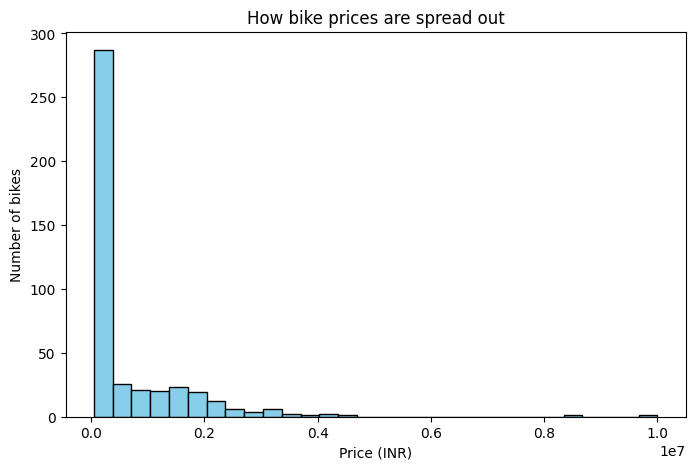

count    4.320000e+02
mean     6.596023e+05
std      1.023870e+06
min      4.791800e+04
25%      1.167242e+05
50%      1.992235e+05
75%      8.720000e+05
max      1.000000e+07
Name: price_min, dtype: float64


In [24]:
plt.figure(figsize=(8,5))
plt.hist(df["price_min"], bins=30, color="skyblue", edgecolor="black")
plt.xlabel("Price (INR)")
plt.ylabel("Number of bikes")
plt.title("How bike prices are spread out")
plt.show()

print(df["price_min"].describe())

The bike price distribution is highly right-skewed, with most bikes priced below ₹1 lakh and a few expensive bikes acting as potential outliers.

2.  **Which brands have the most bikes**

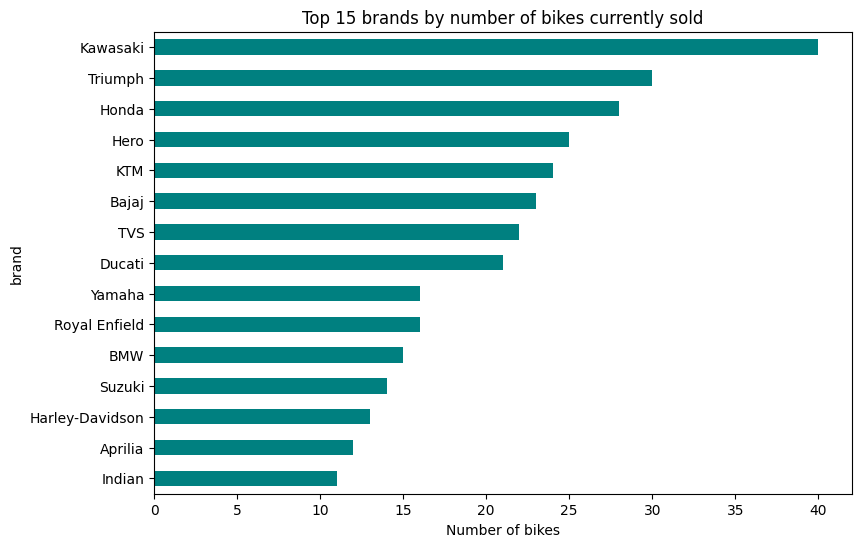

In [25]:
brand_counts = df["brand"].value_counts().head(15)

plt.figure(figsize=(9,6))
brand_counts.plot(kind="barh", color="teal")
plt.xlabel("Number of bikes")
plt.title("Top 15 brands by number of bikes currently sold")
plt.gca().invert_yaxis()
plt.show()

# **3. Petrol vs Electric**

fuel_type
Petrol            332
Electric           99
CNG and Petrol      1
Name: count, dtype: int64


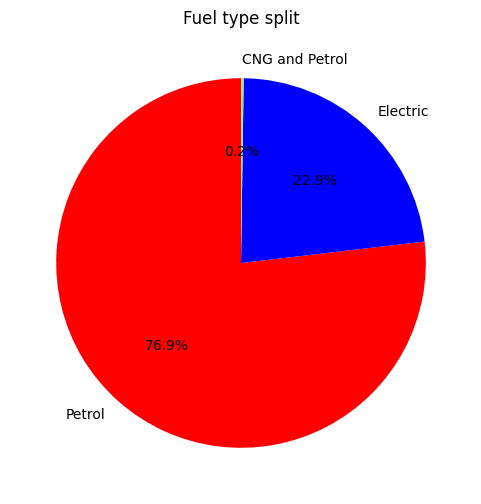

In [30]:
fuel_counts = df["fuel_type"].value_counts()
print(fuel_counts)

plt.figure(figsize=(6,6))
plt.pie(fuel_counts, labels=fuel_counts.index, autopct="%1.1f%%", startangle=90,colors=["red", "blue", "lightgreen", "violet"])
plt.title("Fuel type split")
plt.show()

4. **Rating distribution**

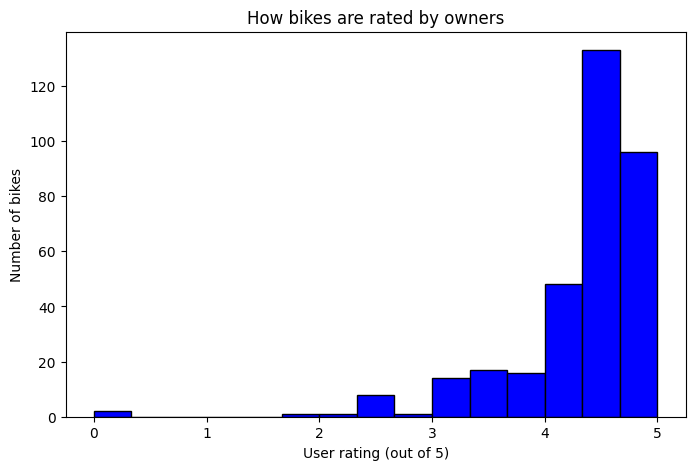

count    337.000000
mean       4.313353
std        0.651212
min        0.000000
25%        4.200000
50%        4.500000
75%        4.700000
max        5.000000
Name: user_rating, dtype: float64


In [33]:
plt.figure(figsize=(8,5))
plt.hist(df["user_rating"].dropna(), bins=15, color="blue", edgecolor="black")
plt.xlabel("User rating (out of 5)")
plt.ylabel("Number of bikes")
plt.title("How bikes are rated by owners")
plt.show()

print(df["user_rating"].describe())

Most ratings are between 4 and 5. Not many bikes have a low rating. This could mean people who buy a bike and leave a review are usually happy owners.

5. **Mileage distribution**

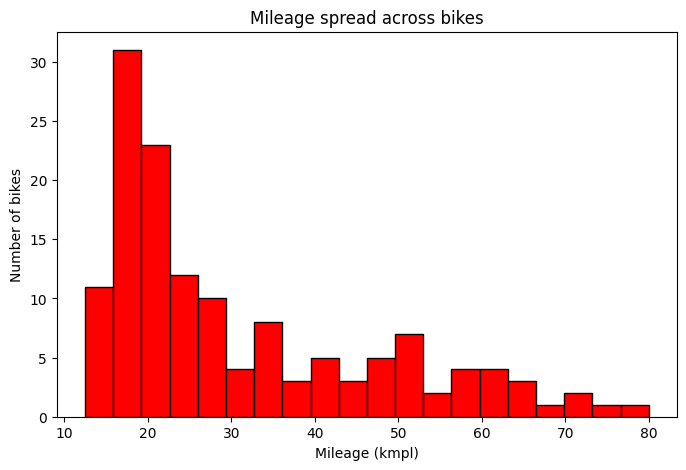

In [34]:
plt.figure(figsize=(8,5))
plt.hist(df["mileage_arai_kmpl"].dropna(), bins=20, color="red", edgecolor="black")
plt.xlabel("Mileage (kmpl)")
plt.ylabel("Number of bikes")
plt.title("Mileage spread across bikes")
plt.show()

6. **Engine size (cc) distribution**

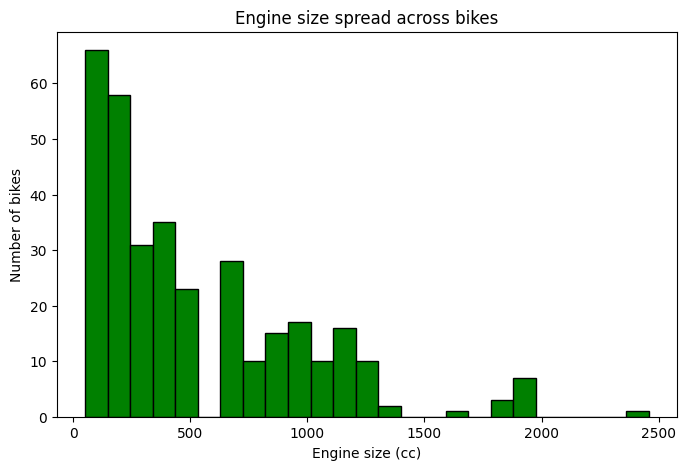

In [36]:
plt.figure(figsize=(8,5))
plt.hist(df["displacement_cc"].dropna(), bins=25, color="green", edgecolor="black")
plt.xlabel("Engine size (cc)")
plt.ylabel("Number of bikes")
plt.title("Engine size spread across bikes")
plt.show()

Part 2: **Bivariate Analysis**

7. **Price vs Mileage**

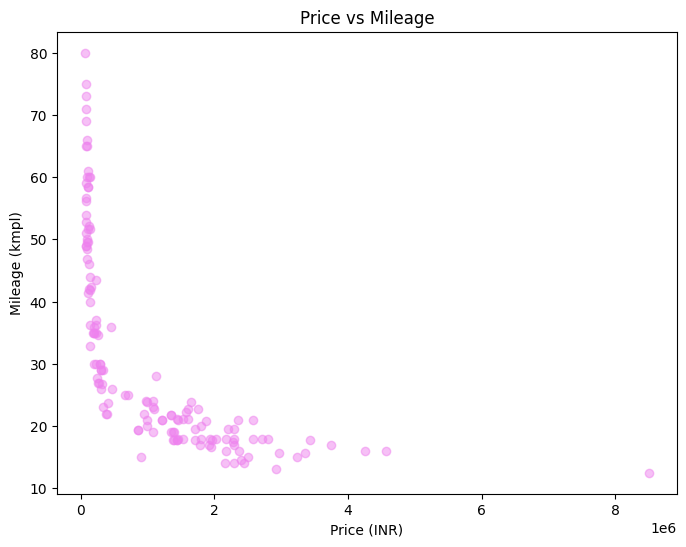

Correlation: -0.6585023199049093


In [37]:
plt.figure(figsize=(8,6))
plt.scatter(df["price_min"], df["mileage_arai_kmpl"], alpha=0.5, color="violet")
plt.xlabel("Price (INR)")
plt.ylabel("Mileage (kmpl)")
plt.title("Price vs Mileage")
plt.show()

print("Correlation:", df["price_min"].corr(df["mileage_arai_kmpl"]))


The correlation is negative (around -0.66). This means as price goes up, mileage usually goes down. Costly bikes are mostly big powerful bikes, and big engines give less mileage.

8. **Price vs Power**

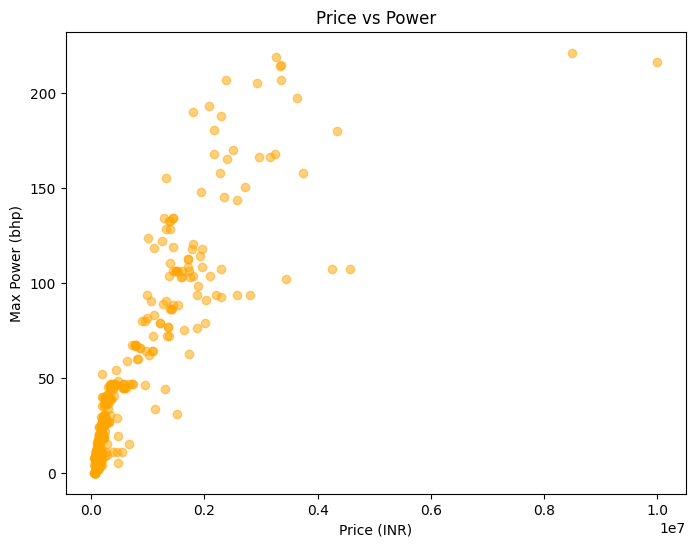

Correlation: 0.8525999998830855


In [39]:
plt.figure(figsize=(8,6))
plt.scatter(df["price_min"], df["max_power_bhp"], alpha=0.5, color="orange")
plt.xlabel("Price (INR)")
plt.ylabel("Max Power (bhp)")
plt.title("Price vs Power")
plt.show()

print("Correlation:", df["price_min"].corr(df["max_power_bhp"]))

9. **Price vs Rating**

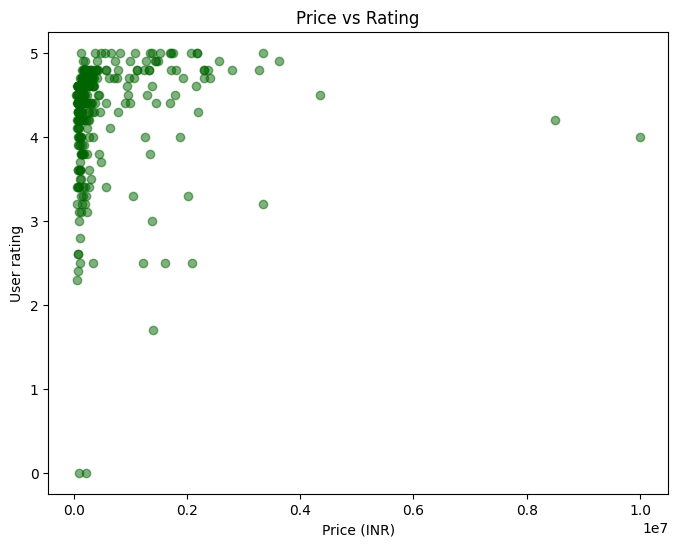

Correlation: 0.07464937578753185


In [40]:
plt.figure(figsize=(8,6))
plt.scatter(df["price_min"], df["user_rating"], alpha=0.5, color="darkgreen")
plt.xlabel("Price (INR)")
plt.ylabel("User rating")
plt.title("Price vs Rating")
plt.show()

print("Correlation:", df["price_min"].corr(df["user_rating"]))

Correlation is close to 0 (around 0.07). This means price does not really decide the rating. A cheap bike can be rated just as high as a costly bike. Good news for budget buyers!

10.**Brand vs average price**

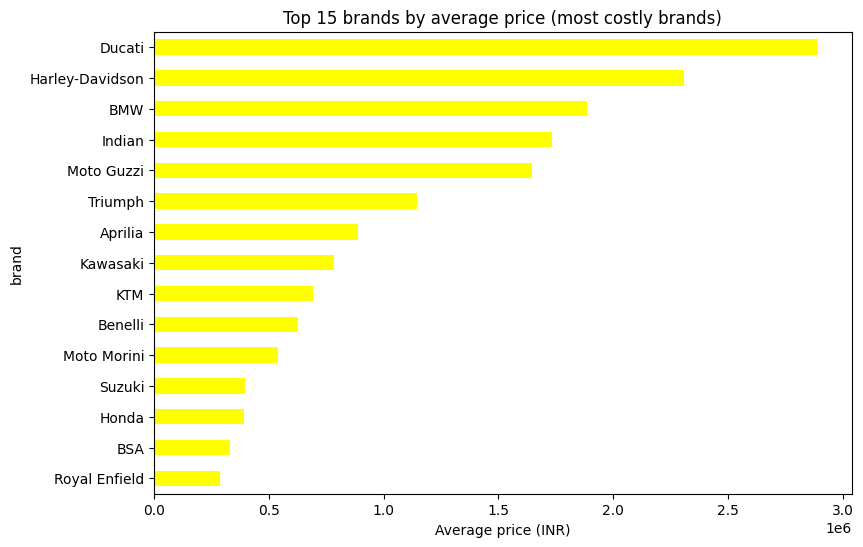

In [42]:
brand_avg_price = df.groupby("brand")["price_min"].mean().sort_values(ascending=False).head(15)

plt.figure(figsize=(9,6))
brand_avg_price.plot(kind="barh", color="yellow")
plt.xlabel("Average price (INR)")
plt.title("Top 15 brands by average price (most costly brands)")
plt.gca().invert_yaxis()
plt.show()

# **11. Enigne size vs Mileage**

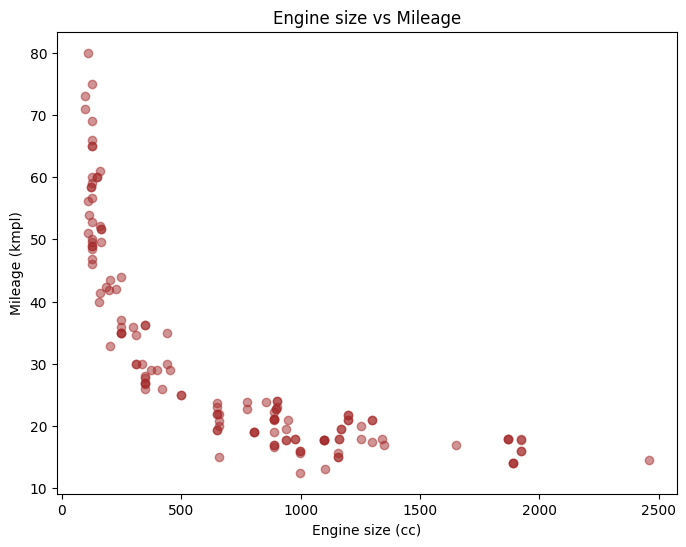

In [43]:
plt.figure(figsize=(8,6))
plt.scatter(df["displacement_cc"], df["mileage_arai_kmpl"], alpha=0.5, color="brown")
plt.xlabel("Engine size (cc)")
plt.ylabel("Mileage (kmpl)")
plt.title("Engine size vs Mileage")
plt.show()

12.**Engine size vs Power**

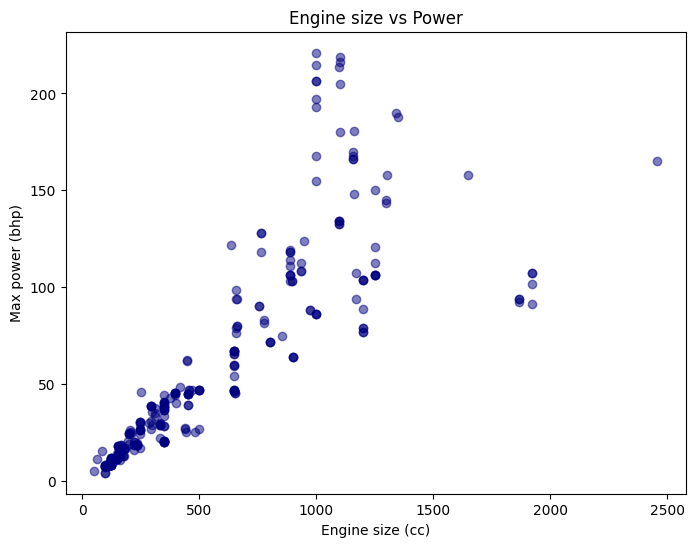

In [46]:
plt.figure(figsize=(8,6))
plt.scatter(df["displacement_cc"], df["max_power_bhp"], alpha=0.5, color="navy")
plt.xlabel("Engine size (cc)")
plt.ylabel("Max power (bhp)")
plt.title("Engine size vs Power")
plt.show()

13.**Fuel type vs Price**

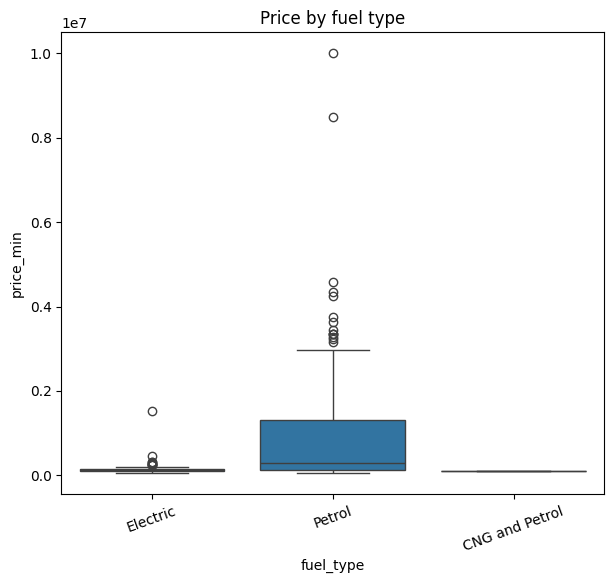

fuel_type
CNG and Petrol     95000.000000
Electric          145508.434343
Petrol            814602.018072
Name: price_min, dtype: float64


In [47]:
plt.figure(figsize=(7,6))
sns.boxplot(data=df, x="fuel_type", y="price_min")
plt.title("Price by fuel type")
plt.xticks(rotation=20)
plt.show()

print(df.groupby("fuel_type")["price_min"].mean())

**14.Fuel type vs Rating**

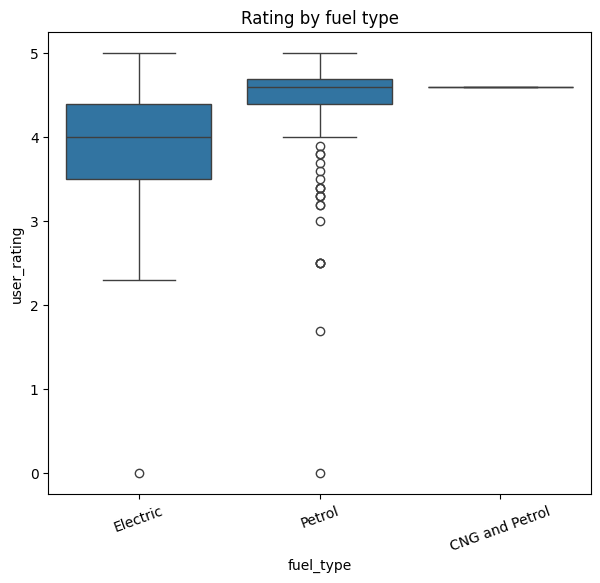

fuel_type
CNG and Petrol    4.600000
Electric          3.880247
Petrol            4.449804
Name: user_rating, dtype: float64


In [48]:
plt.figure(figsize=(7,6))
sns.boxplot(data=df, x="fuel_type", y="user_rating")
plt.title("Rating by fuel type")
plt.xticks(rotation=20)
plt.show()

print(df.groupby("fuel_type")["user_rating"].mean())

# **Part 3 : Multivariate Analysis (Business Insights)**

**15. Top 10 best bikes overall (combined score)**

To find the "best" bike, I cannot look at just price or just power. I made a simple score using 4 things together: price (lower is better), power, mileage, and rating.

I converted each column to a 0 to 1 scale first (this is called min-max scaling), so that price (which is in lakhs) and rating (which is out of 5) can be compared fairly. Then I took the average of all 4 scores

In [49]:
score_df = df.dropna(subset=["price_min","max_power_bhp","mileage_arai_kmpl","user_rating"]).copy()

# scale each column between 0 and 1
score_df["price_score"] = 1 - (score_df["price_min"] - score_df["price_min"].min()) / (score_df["price_min"].max() - score_df["price_min"].min())
score_df["power_score"] = (score_df["max_power_bhp"] - score_df["max_power_bhp"].min()) / (score_df["max_power_bhp"].max() - score_df["max_power_bhp"].min())
score_df["mileage_score"] = (score_df["mileage_arai_kmpl"] - score_df["mileage_arai_kmpl"].min()) / (score_df["mileage_arai_kmpl"].max() - score_df["mileage_arai_kmpl"].min())
score_df["rating_score"] = (score_df["user_rating"] - score_df["user_rating"].min()) / (score_df["user_rating"].max() - score_df["user_rating"].min())

# average of all 4 scores
score_df["final_score"] = (score_df["price_score"] + score_df["power_score"] + score_df["mileage_score"] + score_df["rating_score"]) / 4

top10 = score_df.sort_values("final_score", ascending=False).head(10)
top10[["bike_name","price_min","max_power_bhp","mileage_arai_kmpl","user_rating","final_score"]]

,bike_name,price_min,max_power_bhp,mileage_arai_kmpl,user_rating,final_score
374,TVS Sport,65714,8.08,80.0,4.4,0.704757
122,Hero Splendor Plus Xtec,81360,7.90,73.0,4.6,0.693307
119,Hero Passion Plus,79534,7.91,71.0,4.6,0.685966
125,Hero Super Splendor Xtec,83928,10.72,69.0,4.5,0.674149
124,Hero Super Splendor Xtec 2.0,85925,10.70,75.0,4.2,0.673561
131,Hero Xtreme 125R,92841,11.40,66.0,4.6,0.671147
113,Hero Glamour X 125,89562,11.40,65.0,4.6,0.667541
326,Suzuki Hayabusa,1806885,190.00,18.0,4.8,0.667235
66,BMW S1000RR,2375000,206.51,16.0,4.8,0.662355
342,Triumph Speed Triple 1200 RS,2175900,180.50,18.0,5.0,0.660302


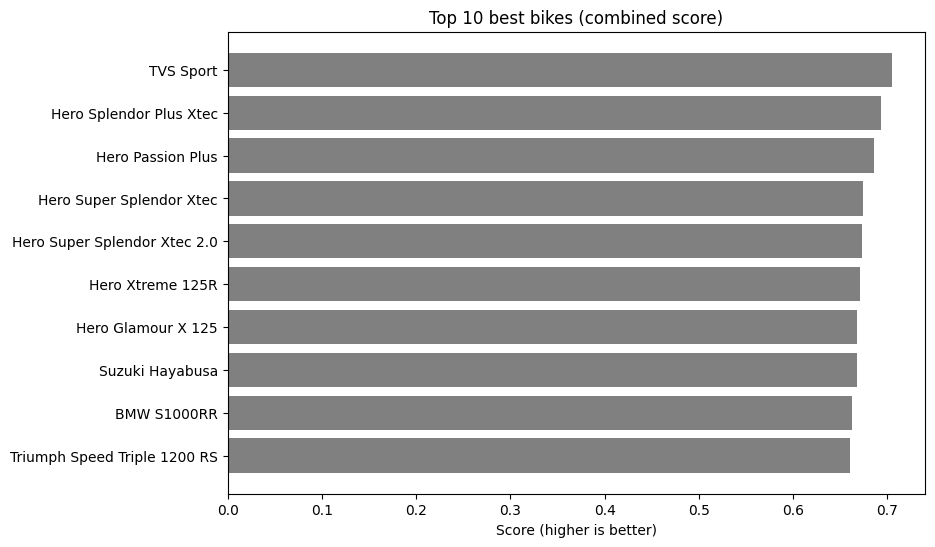

In [51]:
plt.figure(figsize=(9,6))
plt.barh(top10["bike_name"], top10["final_score"], color="grey")
plt.xlabel("Score (higher is better)")
plt.title("Top 10 best bikes (combined score)")
plt.gca().invert_yaxis()
plt.show()

- TVS Sport ranks first with the highest combined score of approximately 0.70, followed by Hero Splendor Plus Xtec.

- The top 10 bikes have relatively similar scores, ranging from approximately 0.66 to 0.70.

- These rankings indicate the best-performing bikes based on the combined scoring criteria used in the analysis.

**16.Best rated bike in each price group**

In [52]:
for band in ["Budget", "Mid", "Premium"]:
    sub = df[df["price_band"] == band].dropna(subset=["user_rating"])
    best = sub.loc[sub["user_rating"].idxmax()]
    print(band, "-> Best rated bike:", best["bike_name"], "| Rating:", best["user_rating"], "| Price:", best["price_min"])

Budget -> Best rated bike: Vespa S 125 | Rating: 5.0 | Price: 136961
Mid -> Best rated bike: Odysse Vader | Rating: 4.9 | Price: 161574
Premium -> Best rated bike: Aprilia RSV4 1100 Factory | Rating: 5.0 | Price: 3340763


**17.Best mileage-for-money bikes**

In [53]:
m = df.dropna(subset=["mileage_arai_kmpl","price_min"]).copy()
m["mileage_per_lakh"] = m["mileage_arai_kmpl"] / (m["price_min"] / 100000)

top_mileage_value = m.sort_values("mileage_per_lakh", ascending=False).head(10)
top_mileage_value[["bike_name","mileage_arai_kmpl","price_min","mileage_per_lakh"]]

,bike_name,mileage_arai_kmpl,price_min,mileage_per_lakh
374,TVS Sport,80.0,65714,121.739660
122,Hero Splendor Plus Xtec,73.0,81360,89.724680
119,Hero Passion Plus,71.0,79534,89.269998
124,Hero Super Splendor Xtec 2.0,75.0,85925,87.285423
125,Hero Super Splendor Xtec,69.0,83928,82.213326
114,Hero Glamour,65.0,85002,76.468789
113,Hero Glamour X 125,65.0,89562,72.575423
110,Hero Destini 110,56.2,77527,72.490874
111,Hero Destini 125,59.0,81700,72.215422
131,Hero Xtreme 125R,66.0,92841,71.089282


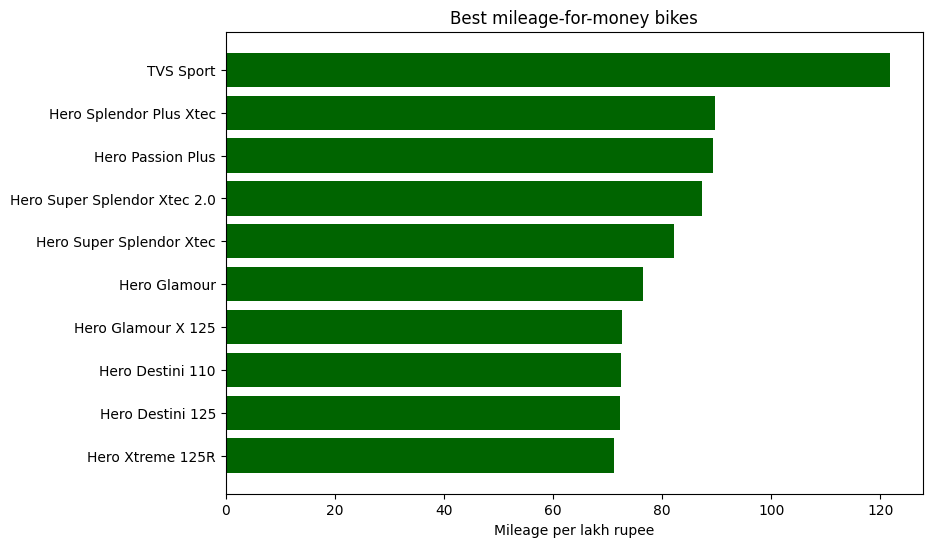

In [54]:
plt.figure(figsize=(9,6))
plt.barh(top_mileage_value["bike_name"], top_mileage_value["mileage_per_lakh"], color="darkgreen")
plt.xlabel("Mileage per lakh rupee")
plt.title("Best mileage-for-money bikes")
plt.gca().invert_yaxis()
plt.show()

**18.ABS availability by price band**

price_band
Budget     33.908046
Mid        84.782609
Premium    93.373494
Name: has_abs, dtype: float64


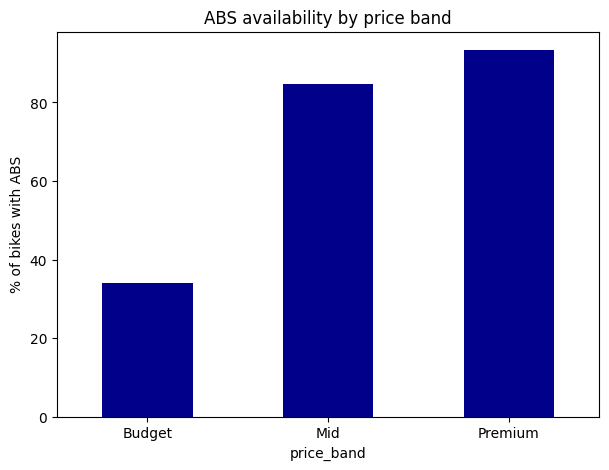

In [56]:
df["has_abs"] = df["abs_type"].str.contains("ABS", case=False, na=False)

abs_by_band = df.groupby("price_band")["has_abs"].mean() * 100
print(abs_by_band)

plt.figure(figsize=(7,5))
abs_by_band.plot(kind="bar", color="darkblue")
plt.ylabel("% of bikes with ABS")
plt.title("ABS availability by price band")
plt.xticks(rotation=0)
plt.show()

**19.Price band makeup by brand**

price_band  Budget  Mid  Premium
brand                           
Hero            22    3        0
Honda           15    8        5
KTM              0    8       16
Kawasaki         1    6       33
Triumph          0    7       23


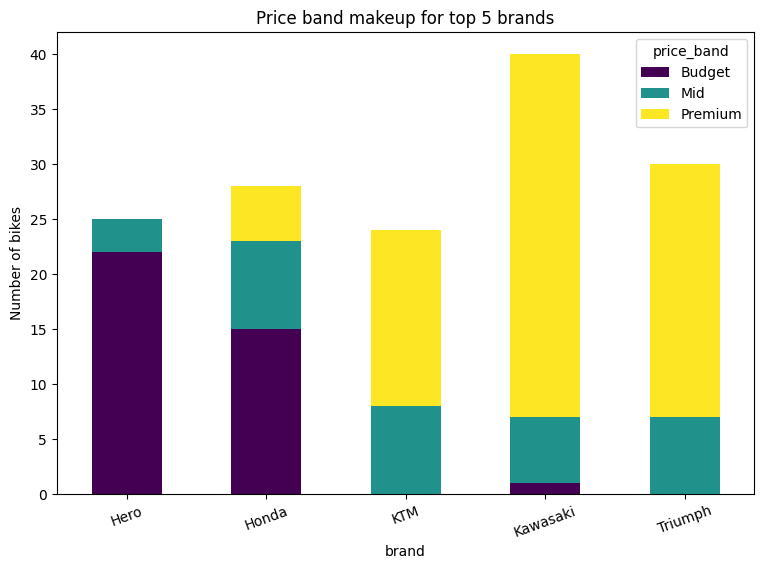

In [60]:
top_brands = df["brand"].value_counts().head(5).index
brand_band_table = df[df["brand"].isin(top_brands)].groupby(["brand","price_band"]).size().unstack(fill_value=0)
print(brand_band_table)

brand_band_table.plot(kind="bar", stacked=True, figsize=(9,6), colormap="viridis")
plt.ylabel("Number of bikes")
plt.title("Price band makeup for top 5 brands")
plt.xticks(rotation=20)
plt.show()

**Summary of Key Findings**

Price vs Power has a strong positive link (corr ~0.85)

 - costly bikes give more power.
Price vs Mileage has a negative link (corr ~-0.66)
 - costly bikes usually give less mileage.
Price vs Rating has almost no link (corr ~0.07)
 - a cheap bike can be rated just as well as a costly one.

Most bikes are rated between 4 and 5 stars.
Hero, Honda, Kawasaki, Triumph, KTM are among the top brands by number of models.

ABS is far more common in Mid/Premium bikes than Budget bikes (35% vs 87-93%).

The overall "best bike" score favours cheap, high-mileage commuter bikes when price, power, mileage and rating are weighted equally - this shows why the price band / best-per-segment view (finding #16) is also important, not just one single ranking.

# **Overall Summary (Top Takeaways)**

Power costs money — there is no shortcut.
Mileage and price don't go together — you trade one for the other.

Cheap bikes can be just as loved by owners as costly ones.

Budget bikes need better ABS availability — a real safety gap.

"Best bike" is not one answer — it depends on what the buyer wants.

Every price group has a genuinely well-rated bike option.

Hero and TVS are the smart pick for fuel-saving commuters.

Brands have clear price-zone strategies (Hero = budget, Kawasaki/Triumph = premium).
Electric bikes are cheap but need to improve owner satisfaction.

Indian, Benelli, BMW, Zontes and KTM lead in owner happiness.